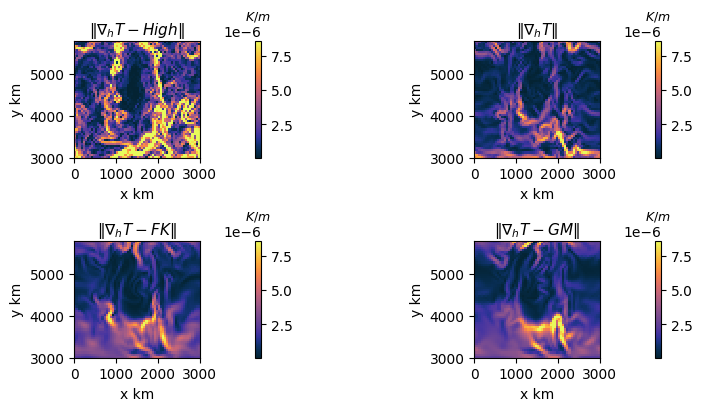

In [13]:
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
from src.utils import T_grad
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low_GM = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km_withoutGM/verification/tutorial_reentrant_channel/run/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
# grid_dir = path_scratch + path_MITgcm
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
# 
# submesoscale heat flux
# high-resolution
box_j, box_i = 10, 10
W = read_mitgcm._ocean_var(path_scratch + path_low, "W", 2376000, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_low, "T", 2376000, ("k","j","i"))
W_FK = read_mitgcm._ocean_var(path_scratch + path_low_FK, "W", 2376000, ("k_l","j","i"))
T_FK = read_mitgcm._ocean_var(path_scratch + path_low_FK, "T", 2376000, ("k","j","i"))
W_GM = read_mitgcm._ocean_var(path_scratch + path_low_GM, "W", 2376000, ("k_l","j","i"))
T_GM = read_mitgcm._ocean_var(path_scratch + path_low_GM, "T", 2376000, ("k","j","i"))
W_high = read_mitgcm._ocean_var(path_scratch + path_high, "W", 14926176, ("k_l","j","i"))
T_high = read_mitgcm._ocean_var(path_scratch + path_high, "T", 14926176, ("k","j","i"))
# ds
ds_ocean = xr.Dataset(dict(T = T, W = W))
ds_ocean_FK = xr.Dataset(dict(T = T_FK, W = W_FK))
ds_ocean_GM = xr.Dataset(dict(T = T_GM, W = W_GM))
Tem_g_FK = T_grad.T_grad(ds_50, ds_ocean_FK, boundary_Y = "fill")
Tem_g = T_grad.T_grad(ds_50, ds_ocean, boundary_Y = "fill")
Tem_g_GM = T_grad.T_grad(ds_50, ds_ocean_GM, boundary_Y = "fill")
T_high_c = coarsen_UVWTS.coarse_field("T", T_high, ds_fine, box_j, box_i)
W_high_c = coarsen_UVWTS.coarse_field("W", W_high, ds_fine, box_j, box_i)
ds_ocean_coarse = xr.Dataset(dict(T = T_high_c, W = W_high_c))
Tem_g_high = T_grad.T_grad(ds_coarse, ds_ocean_coarse, boundary_Y = "fill")


# 

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"‖$\nabla_h T - High$‖":         {"Z": Tem_g_high[0,60:116,:],  "units": r"$K/m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"‖$\nabla_h T$‖":         {"Z": Tem_g[0,60:116,:],  "units": r"$K/m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"‖$\nabla_h T - FK$‖":         {"Z": Tem_g_FK[0,60:116,:],  "units": r"$K/m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"‖$\nabla_h T - GM$‖":         {"Z": Tem_g_GM[0,60:116,:],  "units": r"$K/m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(Tem_g[0,60:116,:], q=0.995)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)
# Plot: 2×5
fig, axes = plt.subplots(2,2, figsize=(8, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    # norm = meta["norm"]
    norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
# fig.savefig("./temperature_gradient.png")
plt.show()